# Retail Price Elasticity & Demand Analysis

**Objective:**  
To calculate the Price Elasticity of Demand (PED) across retail product lines. This model identifies which products are highly sensitive to price changes (prime candidates for promotional discounts to drive volume) and which are inelastic (resilient to price hikes for margin optimization).

**Tech Stack:** Python (Pandas, NumPy, SciPy, Seaborn), Microsoft Excel

**Methodology:** 
1. **Data Engineering:** Cleaned and aggregated raw 2023–2024 transactional sales records into chronological weekly cohorts using Excel PivotTables.
2. **Data Transformation:** Forward-filled null values and applied logarithmic transformations to weekly sales volumes and average unit prices.
3. **Statistical Modeling:** Executed a log-log linear regression (`scipy.stats.linregress`) to extract the exact PED coefficient, R-squared values, and P-values for statistical significance.
4. **Data Visualization:** Plotted the inverse economic relationship between log-price and log-quantity, complete with regression trendlines and statistical confidence intervals.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

# Load the aggregated CSV from your Desktop
df = pd.read_csv('aggregated_weekly_sales.csv')

# Standardize the column names to remove spaces generated by the Excel PivotTable
df.columns = ['Product_Name', 'Week', 'Sum_Quantity', 'Avg_Price']

# Apply log transformation to the target variables
df['log_qty'] = np.log(df['Sum_Quantity'])
df['log_price'] = np.log(df['Avg_Price'])

# Verify the transformation was successful
df.head()

,Product_Name,Week,Sum_Quantity,Avg_Price,log_qty,log_price
0,Adidas Tracksuit,2023-W01,45.0,220.053044,3.806662,5.393869
1,NaN,2023-W02,75.0,223.472821,4.317488,5.409290
2,NaN,2023-W03,74.0,225.251177,4.304065,5.417216
3,NaN,2023-W04,106.0,256.870769,4.663439,5.548573
4,NaN,2023-W05,52.0,238.111154,3.951244,5.472738


In [4]:
# Forward-fill the blank product names left by the Excel PivotTable
df['Product_Name'] = df['Product_Name'].ffill()

# Create an empty list to store our mathematical outputs
elasticity_results = []

# Loop through every unique product in your dataset
for product in df['Product_Name'].unique():
    # Isolate the data for just this specific item
    product_data = df[df['Product_Name'] == product]
    
    # We need at least 4 weeks of sales data to draw a statistically valid trendline
    if len(product_data) > 3:
        # Run the log-log linear regression (X = log_price, Y = log_qty)
        slope, intercept, r_value, p_value, std_err = stats.linregress(product_data['log_price'], product_data['log_qty'])
        
        # Append the calculated metrics to our list
        elasticity_results.append({
            'Product_Name': product,
            'Price_Elasticity': slope,
            'R_Squared': r_value**2, # Measures how well price explains the changes in volume
            'P_Value': p_value,      # Measures statistical significance
            'Weeks_Sold': len(product_data)
        })

# Convert the final results into a clean DataFrame
elasticity_df = pd.DataFrame(elasticity_results)

# Sort by elasticity (lowest negative numbers first, meaning highly elastic)
elasticity_df = elasticity_df.sort_values(by='Price_Elasticity')

# Display the top 10 most price-sensitive items
elasticity_df.head(10)

,Product_Name,Price_Elasticity,R_Squared,P_Value,Weeks_Sold
38,Sunglasses,-1.328944,0.029206,0.082822,104
39,Tempur-Pedic Mattress,-1.291697,0.016184,0.198124,104
35,Samsung Galaxy Tab,-1.203130,0.046512,0.027897,104
25,Levi's Jeans,-0.842294,0.024142,0.115263,104
6,Bose Soundbar,-0.833575,0.031388,0.071993,104
13,Crocs,-0.718249,0.014793,0.218724,104
45,Wall Art,-0.625820,0.021701,0.135619,104
46,Wallet,-0.598582,0.007097,0.395184,104
5,Belt,-0.589907,0.009764,0.318292,104
29,Nike Running Shoes,-0.571572,0.011348,0.281799,104


Matplotlib is building the font cache; this may take a moment.


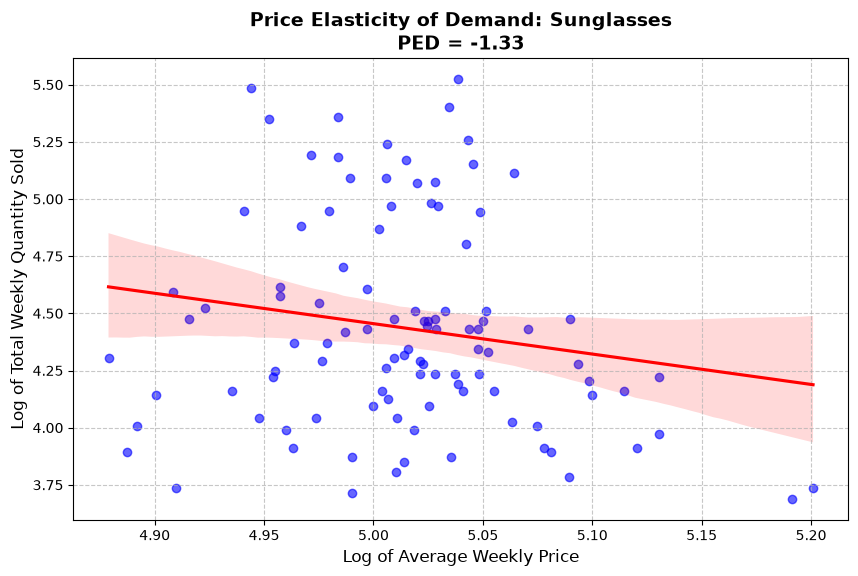

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the name of the most elastic product from your results
top_product = elasticity_df.iloc[0]['Product_Name']
top_ped = elasticity_df.iloc[0]['Price_Elasticity']

# Isolate the data for this specific product
plot_data = df[df['Product_Name'] == top_product]

# Set up the visualization
plt.figure(figsize=(10, 6))
sns.regplot(
    x='log_price', 
    y='log_qty', 
    data=plot_data, 
    scatter_kws={'alpha':0.6, 'color':'blue'}, 
    line_kws={'color':'red'}
)

# Format the chart for a professional portfolio
plt.title(f'Price Elasticity of Demand: {top_product}\nPED = {top_ped:.2f}', fontsize=14, fontweight='bold')
plt.xlabel('Log of Average Weekly Price', fontsize=12)
plt.ylabel('Log of Total Weekly Quantity Sold', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

In [6]:
import sys
!{sys.executable} -m pip install matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 3.4 MB/s eta 0:00:0000:0100:010m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 3.8 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.1/270.1 kB 4.3 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 3.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.1/64.1 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 2.9 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: pip3.11 install --upgrade pip


In [1]:
import sys
!{sys.executable} -m pip install pandas numpy scipy


[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: pip3.11 install --upgrade pip
